# EN4554 Assignment 2: CNNs
**Name:** Gunasekara V.G.V.  
**Index:** 220193M  
**GitHub:** https://github.com/venumigihansa/EN4554-Assignment-2/blob/main/220193M_a02.ipynb

## Setup and data split

In [ ]:
import random
import numpy as np
import torch
import torchvision

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', device)

train_full = torchvision.datasets.CIFAR10('./data', train=True, download=True)
test_set = torchvision.datasets.CIFAR10('./data', train=False, download=True)
CLASSES = train_full.classes

# uint8 (N, 32, 32, 3) -> float (N, 3, 32, 32) in [0, 1]
def to_tensor(ds):
    X = torch.from_numpy(ds.data).permute(0, 3, 1, 2).float().div(255)
    y = torch.tensor(ds.targets)
    return X, y

X_full, y_full = to_tensor(train_full)
X_test, y_test = to_tensor(test_set)  # used only once, in Task 4

perm = torch.randperm(len(X_full), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]
X_train, y_train = X_full[train_idx], y_full[train_idx]
X_val, y_val = X_full[val_idx], y_full[val_idx]
del X_full, y_full

print('train:', tuple(X_train.shape), 'val:', tuple(X_val.shape), 'test:', tuple(X_test.shape))
print('val class counts:', torch.bincount(y_val, minlength=10).tolist())

device: cuda
train: (45000, 3, 32, 32) val: (5000, 3, 32, 32) test: (10000, 3, 32, 32)
val class counts: [488, 512, 532, 471, 471, 514, 507, 500, 504, 501]


## Preprocessing

In [2]:
MEAN = X_train.mean(dim=(0, 2, 3))
STD = X_train.std(dim=(0, 2, 3))
print('mean:', MEAN.tolist())
print('std: ', STD.tolist())

def normalize(X):
    return (X - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)

X_train, X_val, X_test = normalize(X_train), normalize(X_val), normalize(X_test)

class TensorLoader:
    """Minimal batched loader over in-memory tensors (much faster than DataLoader per-sample indexing)."""
    def __init__(self, X, y, batch_size=128, shuffle=False, seed=SEED):
        self.X, self.y, self.bs, self.shuffle = X, y, batch_size, shuffle
        self.g = torch.Generator().manual_seed(seed)

    def __iter__(self):
        n = len(self.X)
        idx = torch.randperm(n, generator=self.g) if self.shuffle else torch.arange(n)
        for i in range(0, n, self.bs):
            j = idx[i:i + self.bs]
            yield self.X[j], self.y[j]

    def __len__(self):
        return (len(self.X) + self.bs - 1) // self.bs

train_loader = TensorLoader(X_train, y_train, batch_size=128, shuffle=True)
val_loader = TensorLoader(X_val, y_val, batch_size=512)

xb, yb = next(iter(train_loader))
print('batch:', tuple(xb.shape), 'normalized train mean/std:',
      X_train.mean(dim=(0, 2, 3)).tolist(), X_train.std(dim=(0, 2, 3)).tolist())

mean: [0.49165481328964233, 0.4823332130908966, 0.4466792047023773]
std:  [0.24708116054534912, 0.2435086965560913, 0.2615806758403778]


batch: (128, 3, 32, 32) normalized train mean/std: [3.6698620533570647e-06, 3.482382226138725e-06, 1.3839404289228696e-07] [1.0, 1.0, 0.9999999403953552]


## Task 1: Backpropagation

### 1(a) Linear, ReLU and cross-entropy layers

In [3]:
# Task 1(a): Linear, ReLU, softmax cross-entropy with manual forward/backward, and an MLP
import math
import matplotlib.pyplot as plt

class Linear:
    def __init__(self, in_f, out_f, init='kaiming', dtype=torch.float32, device='cpu'):
        std = math.sqrt(2 / in_f) if init == 'kaiming' else math.sqrt(2 / (in_f + out_f))  # He / Xavier
        self.W = torch.randn(in_f, out_f, dtype=dtype, device=device) * std
        self.b = torch.zeros(out_f, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values      # numerical stability
        log_probs = shifted - shifted.exp().sum(dim=1, keepdim=True).log()
        self.probs, self.y = log_probs.exp(), y
        return -log_probs[torch.arange(len(y)), y].mean()

    def backward(self):
        d = self.probs.clone()
        d[torch.arange(len(self.y)), self.y] -= 1
        return d / len(self.y)


class MLP:
    def __init__(self, sizes, act=ReLU, init='kaiming', dtype=torch.float32, device='cpu'):
        self.layers = []
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(a, b, init, dtype, device))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.criterion = SoftmaxCrossEntropy()

    @property
    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def forward(self, x):
        for l in self.layers:
            x = l.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):
        d = self.criterion.backward()
        for l in reversed(self.layers):
            d = l.backward(d)

    def params_and_grads(self):
        out = []
        for i, l in enumerate(self.linears):
            out += [(f'W{i+1}', l.W, l.dW), (f'b{i+1}', l.b, l.db)]
        return out

### 1(b) Gradient check

In [4]:
# Task 1(b): gradient check vs autograd and centred finite differences (float64, CPU)
import torch.nn.functional as F
set_seed()
dt = torch.float64
gc_net = MLP([48, 32, 16, 10], dtype=dt)
xg = torch.randn(16, 48, dtype=dt)
yg = torch.randint(0, 10, (16,))

# manual gradients
gc_net.loss(xg, yg)
gc_net.backward()
manual = {name: g.clone() for name, _, g in gc_net.params_and_grads()}

# autograd on the same weights
ps = [p.clone().requires_grad_(True) for _, p, _ in gc_net.params_and_grads()]
h = xg
for k in range(0, len(ps), 2):
    h = h @ ps[k] + ps[k + 1]
    if k < len(ps) - 2:
        h = torch.relu(h)
F.cross_entropy(h, yg).backward()
auto = {name: p.grad for (name, _, _), p in zip(gc_net.params_and_grads(), ps)}

# centred finite differences
def finite_diff(net, x, y, eps=1e-6):
    grads = {}
    for name, p, _ in net.params_and_grads():
        g = torch.zeros_like(p)
        flat, gflat = p.view(-1), g.view(-1)
        for i in range(flat.numel()):
            old = flat[i].item()
            flat[i] = old + eps; lp = net.loss(x, y).item()
            flat[i] = old - eps; lm = net.loss(x, y).item()
            flat[i] = old
            gflat[i] = (lp - lm) / (2 * eps)
        grads[name] = g
    return grads

numeric = finite_diff(gc_net, xg, yg)

def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-12)).item()

print(f"{'param':>5} | {'rel err (autograd)':>18} {'allclose':>8} | {'rel err (finite diff)':>21} {'allclose':>8}")
for name in manual:
    m, a, n = manual[name], auto[name], numeric[name]
    print(f"{name:>5} | {rel_err(m, a):18.2e} {str(torch.allclose(m, a)):>8} | "
          f"{rel_err(m, n):21.2e} {str(torch.allclose(m, n, rtol=1e-5, atol=1e-7)):>8}")

param | rel err (autograd) allclose | rel err (finite diff) allclose
   W1 |           6.02e-17     True |              1.83e-09     True
   b1 |           7.98e-17     True |              1.50e-09     True
   W2 |           4.61e-17     True |              9.97e-10     True
   b2 |           5.16e-17     True |              1.09e-09     True
   W3 |           4.39e-17     True |              9.34e-10     True
   b3 |           3.08e-17     True |              1.52e-09     True


**Discussion**

- The manual gradients match autograd with a relative error of about 1e-17. This is float64 machine precision, so the two are effectively identical, and `torch.allclose` returns `True` for every parameter.
- Against centred finite differences, the relative error is about 1e-9. This is expected, since finite differences only approximate the derivative: with ε = 1e-6 there is a small truncation error plus some rounding error.
- The check was run in float64 deliberately. In float32, the rounding error would be large enough to hide genuine bugs.

Overall, the backward passes for Linear, ReLU and softmax cross-entropy are correct.


### 1(c) Training the MLP

epoch  1  train loss 1.6991  val loss 1.6025  val acc 0.4322


epoch  2  train loss 1.4184  val loss 1.5262  val acc 0.4614


epoch  3  train loss 1.2894  val loss 1.4740  val acc 0.4882


epoch  4  train loss 1.1850  val loss 1.4910  val acc 0.4860


epoch  5  train loss 1.0977  val loss 1.4602  val acc 0.5150


...

epoch 16  train loss 0.4058  val loss 1.9599  val acc 0.5052


epoch 17  train loss 0.3788  val loss 2.0533  val acc 0.4986


epoch 18  train loss 0.3323  val loss 2.0703  val acc 0.5064


epoch 19  train loss 0.2893  val loss 2.2025  val acc 0.4888


epoch 20  train loss 0.2550  val loss 2.2561  val acc 0.5020


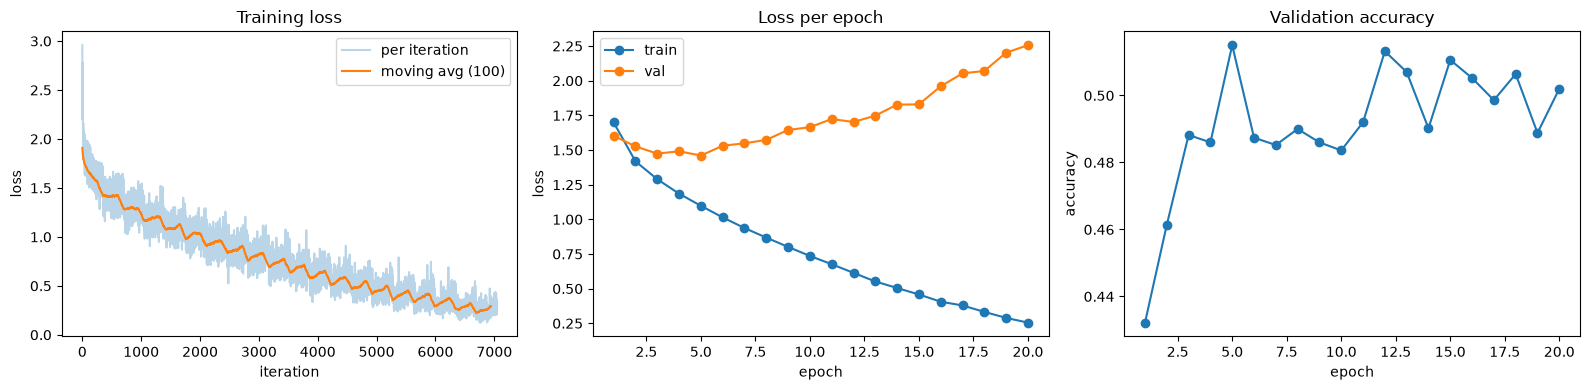

final val acc: 0.5020   best val acc: 0.5150


In [5]:
# Task 1(c): train the MLP with SGD on flattened CIFAR-10
def evaluate_mlp(net, loader):
    correct, total, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.view(len(xb), -1).to(device), yb.to(device)
        logits = net.forward(xb)
        loss_sum += net.criterion.forward(logits, yb).item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(yb)
    return loss_sum / total, correct / total

set_seed()
mlp = MLP([3072, 512, 256, 10], device=device)
lr, epochs = 0.05, 20
hist = {'iter_loss': [], 'train_loss': [], 'val_loss': [], 'val_acc': []}

for ep in range(epochs):
    ep_loss, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.view(len(xb), -1).to(device), yb.to(device)
        loss = mlp.loss(xb, yb)
        mlp.backward()
        for _, p, g in mlp.params_and_grads():
            p -= lr * g
        hist['iter_loss'].append(loss.item())
        ep_loss += loss.item() * len(yb); n += len(yb)
    vl, va = evaluate_mlp(mlp, val_loader)
    hist['train_loss'].append(ep_loss / n); hist['val_loss'].append(vl); hist['val_acc'].append(va)
    print(f'epoch {ep+1:2d}  train loss {ep_loss/n:.4f}  val loss {vl:.4f}  val acc {va:.4f}')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
it = np.array(hist['iter_loss'])
ax[0].plot(it, alpha=0.3, label='per iteration')
ax[0].plot(np.convolve(it, np.ones(100) / 100, mode='valid'), label='moving avg (100)')
ax[0].set(xlabel='iteration', ylabel='loss', title='Training loss'); ax[0].legend()
ep_x = range(1, epochs + 1)
ax[1].plot(ep_x, hist['train_loss'], 'o-', label='train'); ax[1].plot(ep_x, hist['val_loss'], 'o-', label='val')
ax[1].set(xlabel='epoch', ylabel='loss', title='Loss per epoch'); ax[1].legend()
ax[2].plot(ep_x, hist['val_acc'], 'o-')
ax[2].set(xlabel='epoch', ylabel='accuracy', title='Validation accuracy')
plt.tight_layout(); plt.show()
print(f"final val acc: {hist['val_acc'][-1]:.4f}   best val acc: {max(hist['val_acc']):.4f}")

**Discussion**

- The MLP reaches its best validation accuracy of 51.5% at epoch 5, where the validation loss is also lowest (1.46).
- After epoch 5 the network overfits. The training loss keeps falling to 0.26 by epoch 20, while the validation loss rises to 2.26.
- The validation accuracy stays around 49–51% during this phase. This shows the network is becoming more confident in its wrong predictions rather than making many more of them.
- The accuracy is limited because flattening each image into a 3072-value vector discards its spatial structure, so the MLP cannot reuse a learned pattern at different positions in the image.
- With about 1.7 million parameters and no regularisation, the network memorises the training set instead of generalising.
- Early stopping around epoch 5 would give the best model, but the CNNs in later tasks reach around 75% with far fewer parameters.


### 1(d) Gradient norms with sigmoid and ReLU

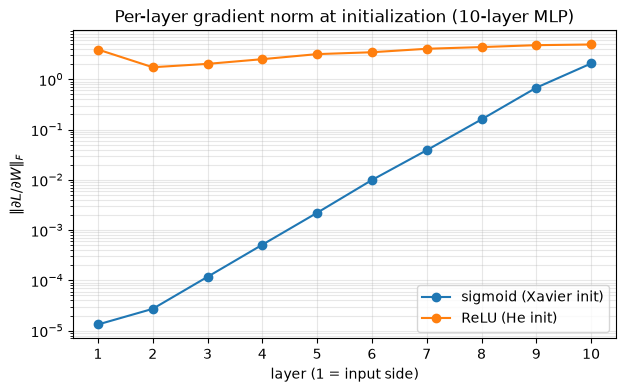

sigmoid (Xavier init)  layer1 / layer10 gradient-norm ratio: 6.42e-06
ReLU (He init)         layer1 / layer10 gradient-norm ratio: 7.95e-01


In [6]:
# Task 1(d): per-layer gradient norms at initialization for a 10-layer MLP, sigmoid vs ReLU
class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)

sizes = [3072] + [256] * 9 + [10]          # 10 Linear layers
xb, yb = X_train[:512].view(512, -1).to(device), y_train[:512].to(device)

grad_norms = {}
for name, act, init in [('sigmoid (Xavier init)', Sigmoid, 'xavier'), ('ReLU (He init)', ReLU, 'kaiming')]:
    set_seed()
    net = MLP(sizes, act=act, init=init, device=device)
    net.loss(xb, yb)
    net.backward()
    grad_norms[name] = [l.dW.norm().item() for l in net.linears]

layers = range(1, len(sizes))
plt.figure(figsize=(7, 4))
for name, g in grad_norms.items():
    plt.semilogy(layers, g, 'o-', label=name)
plt.xticks(layers)
plt.xlabel('layer (1 = input side)'); plt.ylabel(r'$\|\partial L / \partial W\|_F$')
plt.title('Per-layer gradient norm at initialization (10-layer MLP)')
plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.show()

for name, g in grad_norms.items():
    print(f'{name:22s} layer1 / layer10 gradient-norm ratio: {g[0] / g[-1]:.2e}')

**Discussion**

- The ratio printed below the plot is the gradient norm at layer 1 divided by the gradient norm at layer 10. It shows how much the gradient has shrunk by the time it reaches the first layer.
- **Sigmoid (Xavier init):** the gradient shrinks by roughly a factor of 4 at every layer going backwards. At layer 1 it is about 6.4 × 10⁻⁶ times the size at layer 10, a drop of more than five orders of magnitude.
- This happens because the derivative of the sigmoid, σ'(x) = σ(x)(1 − σ(x)), is at most 0.25:

  | x | σ(x) | σ'(x) = σ(1 − σ) |
  |---|---|---|
  | 0 | 0.5 | 0.25 (the maximum) |
  | ±2 | 0.88 / 0.12 | 0.105 |
  | ±5 | 0.993 / 0.007 | 0.0066 |

- Backpropagation multiplies the gradient by this derivative once per layer, so even in the best case it shrinks by a factor of 4 per layer. Over 9 layers this gives 0.25⁹ ≈ 4 × 10⁻⁶, which closely matches the measured ratio. As a result, the early layers would receive almost no gradient and would barely learn during training. This is the vanishing gradient problem.
- **ReLU (He init):** the gradient norm stays nearly constant across all 10 layers. The gradient at layer 1 is 0.80 times the gradient at layer 10, so it is almost the same size.
- This is because the derivative of ReLU is exactly 1 for active units, so the gradient passes through without shrinking. He initialisation scales the weights so that the signal keeps its size even though roughly half of the units output zero.
- Each activation was paired with its standard initialisation (Xavier for sigmoid, He for ReLU), so the vanishing gradient is caused by the small derivative of the sigmoid, not by the choice of initialisation.


## Helper functions for Tasks 2 to 4

In [7]:
# Shared utilities for Tasks 2-4: data on device, training loop, evaluation, GPU augmentations, result caching
import os, math, time, copy, pickle
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

Xtr_d, ytr_d = X_train.to(device), y_train.to(device)
Xva_d, yva_d = X_val.to(device), y_val.to(device)
val_dl = TensorLoader(Xva_d, yva_d, batch_size=512)

RESULTS_DIR = 'results'          # delete a .pkl file here to re-run that experiment
os.makedirs(RESULTS_DIR, exist_ok=True)

def cached(name, fn):
    path = os.path.join(RESULTS_DIR, f'{name}.pkl')
    if os.path.exists(path):
        print(f'[loaded {name}]')
        with open(path, 'rb') as fh:
            return pickle.load(fh)
    out = fn()
    with open(path, 'wb') as fh:
        pickle.dump(out, fh)
    return out

def smooth(x, k=50):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(k) / k, mode='valid') if len(x) > k else x

def n_params(model):
    return sum(p.numel() for p in model.parameters())

# ---------- augmentations (operate on a normalized batch already on the device) ----------
def flip_crop(x, pad=4):
    n, c, h, w = x.shape
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))                      # zero = channel mean after normalization
    i = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    rows = (i[:, None] + torch.arange(h, device=x.device))[:, None, :, None]
    cols = (j[:, None] + torch.arange(w, device=x.device))[:, None, None, :]
    return xp[torch.arange(n, device=x.device)[:, None, None, None],
              torch.arange(c, device=x.device)[None, :, None, None], rows, cols]

def cutout(x, size=16):
    n, _, h, w = x.shape
    cy = torch.randint(0, h, (n, 1), device=x.device)
    cx = torch.randint(0, w, (n, 1), device=x.device)
    ys = torch.arange(h, device=x.device)[None]
    xs = torch.arange(w, device=x.device)[None]
    my = (ys >= cy - size // 2) & (ys < cy + size // 2)
    mx = (xs >= cx - size // 2) & (xs < cx + size // 2)
    mask = my[:, :, None] & mx[:, None, :]
    return x.masked_fill(mask[:, None], 0.0)

def compose(*fns):
    def f(x):
        for fn in fns:
            x = fn(x)
        return x
    return f

# ---------- models ----------
class SmallCNN(nn.Module):
    def __init__(self, bn=False, dropout=0.0):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            return layers + [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(inplace=True),
                                        nn.Dropout(dropout), nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

# ---------- training / evaluation ----------
@torch.no_grad()
def evaluate(model, loader, amp=None):
    amp = (device.type == 'cuda') if amp is None else amp
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            out = model(xb)
        loss_sum += F.cross_entropy(out.float(), yb, reduction='sum')
        correct += (out.argmax(1) == yb).sum()
        n += len(yb)
    return (loss_sum / n).item(), (correct / n).item()

def fit(model, opt, train_dl, epochs, sched=None, sched_per_iter=False, augment=None, mixup_alpha=0.0,
        label_smoothing=0.0, clean_train_dl=None, amp=None, verbose=True):
    """clean_train_dl: if given, train accuracy is measured on un-augmented data in eval mode."""
    amp = (device.type == 'cuda') if amp is None else amp
    scaler = torch.amp.GradScaler('cuda', enabled=amp)
    crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    hist = {k: [] for k in ['iter_loss', 'train_loss', 'train_acc', 'val_loss', 'val_acc']}
    hist['diverged'] = False
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        losses, correct, n = [], 0, 0
        for xb, yb in train_dl:
            if augment is not None:
                xb = augment(xb)
            if mixup_alpha > 0:
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                perm = torch.randperm(len(xb), device=xb.device)
                xb, yb2 = lam * xb + (1 - lam) * xb[perm], yb[perm]
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                out = model(xb)
                loss = crit(out, yb) if mixup_alpha == 0 else lam * crit(out, yb) + (1 - lam) * crit(out, yb2)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            if sched is not None and sched_per_iter:
                sched.step()
            losses.append(loss.detach())
            correct += (out.argmax(1) == yb).sum()
            n += len(yb)
        if sched is not None and not sched_per_iter:
            sched.step()
        ep_losses = torch.stack(losses).float().cpu()
        hist['iter_loss'] += ep_losses.tolist()
        hist['train_loss'].append(ep_losses.mean().item())
        hist['train_acc'].append(evaluate(model, clean_train_dl, amp)[1] if clean_train_dl is not None
                                 else (correct / n).item())
        vl, va = evaluate(model, val_dl, amp)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if verbose:
            print(f'  ep {ep+1:3d}  loss {hist["train_loss"][-1]:.4f}  train acc {hist["train_acc"][-1]:.4f}  '
                  f'val acc {va:.4f}  ({time.time() - t0:.0f}s)')
        if not math.isfinite(hist['train_loss'][-1]):
            hist['diverged'] = True
            print('  diverged, stopping')
            break
    hist['time'] = time.time() - t0
    return hist

## Task 2: Optimizers

### 2(a) SGD with momentum and Adam

In [8]:
# Task 2(a): SGD with momentum and Adam (with bias correction) as torch.optim.Optimizer subclasses
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for g in self.param_groups:
            for p in g['params']:
                if p.grad is None:
                    continue
                d = p.grad
                if g['weight_decay'] != 0:
                    d = d.add(p, alpha=g['weight_decay'])
                if g['momentum'] != 0:
                    st = self.state[p]
                    if 'buf' not in st:
                        st['buf'] = d.clone()                        # v_1 = g_1
                    else:
                        st['buf'].mul_(g['momentum']).add_(d)        # v_t = mu * v_{t-1} + g_t
                    d = st['buf']
                p.add_(d, alpha=-g['lr'])                            # theta -= lr * v_t
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for g in self.param_groups:
            b1, b2 = g['betas']
            for p in g['params']:
                if p.grad is None:
                    continue
                d = p.grad
                if g['weight_decay'] != 0:
                    d = d.add(p, alpha=g['weight_decay'])
                st = self.state[p]
                if not st:
                    st['t'] = 0
                    st['m'] = torch.zeros_like(p)
                    st['v'] = torch.zeros_like(p)
                st['t'] += 1
                st['m'].mul_(b1).add_(d, alpha=1 - b1)               # first moment
                st['v'].mul_(b2).addcmul_(d, d, value=1 - b2)        # second moment
                m_hat = st['m'] / (1 - b1 ** st['t'])                # bias correction
                v_hat = st['v'] / (1 - b2 ** st['t'])
                p.addcdiv_(m_hat, v_hat.sqrt().add_(g['eps']), value=-g['lr'])
        return loss


def compare_optimizers(mine, ref, kwargs, steps=100):
    set_seed()
    base = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 10)).double()
    m1, m2 = copy.deepcopy(base), copy.deepcopy(base)
    o1, o2 = mine(m1.parameters(), **kwargs), ref(m2.parameters(), **kwargs)
    gen = torch.Generator().manual_seed(0)
    for _ in range(steps):
        x = torch.randn(32, 20, generator=gen, dtype=torch.float64)
        y = torch.randint(0, 10, (32,), generator=gen)
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad()
            F.cross_entropy(m(x), y).backward()
            o.step()
    pairs = list(zip(m1.parameters(), m2.parameters()))
    return max((a - b).abs().max().item() for a, b in pairs), all(torch.allclose(a, b) for a, b in pairs)

checks = [
    ('SGD',                MySGD,  torch.optim.SGD,  dict(lr=0.1)),
    ('SGD + momentum',     MySGD,  torch.optim.SGD,  dict(lr=0.1, momentum=0.9)),
    ('SGD + momentum + wd', MySGD, torch.optim.SGD,  dict(lr=0.1, momentum=0.9, weight_decay=1e-3)),
    ('Adam',               MyAdam, torch.optim.Adam, dict(lr=1e-3)),
    ('Adam + wd',          MyAdam, torch.optim.Adam, dict(lr=1e-3, weight_decay=1e-3)),
]
print(f"{'optimizer':22s} {'max |diff| after 100 steps':>27s} {'allclose':>9s}")
for name, mine, ref, kw in checks:
    diff, ok = compare_optimizers(mine, ref, kw)
    print(f'{name:22s} {diff:27.2e} {str(ok):>9s}')

optimizer               max |diff| after 100 steps  allclose
SGD                                       0.00e+00      True
SGD + momentum                            0.00e+00      True
SGD + momentum + wd                       0.00e+00      True
Adam                                      8.33e-17      True


Adam + wd                                 5.55e-17      True


**Discussion**

- **SGD (all three variants):** the difference from `torch.optim.SGD` is exactly 0. The implementation performs the same operations in the same order, so the results are bit-for-bit identical.
- **Adam (with and without weight decay):** the difference is about 1e-16, which is just float64 rounding. The bias-corrected update is written slightly differently from PyTorch's, but the mathematics is the same.
- `torch.allclose` is `True` in all five cases.

Overall, both optimizers are implemented correctly.

### 2(b) Optimizer paths on a quadratic

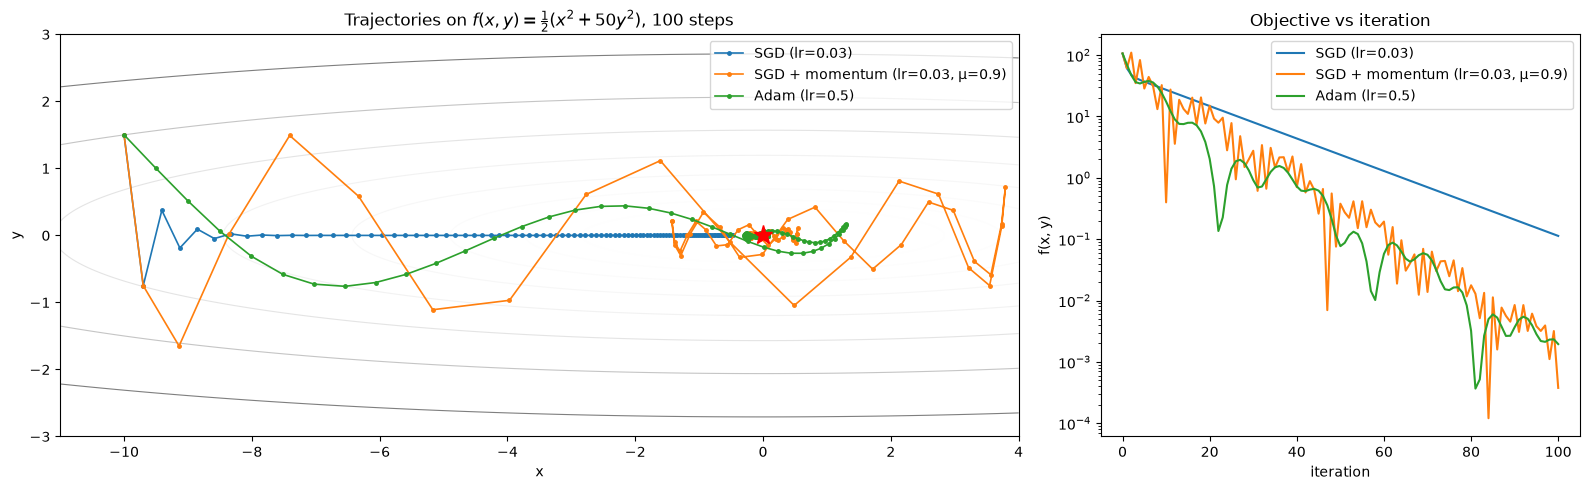

SGD (lr=0.03)                      final point (-0.4755, +0.0000)  f = 1.13e-01
SGD + momentum (lr=0.03, μ=0.9)    final point (+0.0248, -0.0017)  f = 3.77e-04
Adam (lr=0.5)                      final point (+0.0421, +0.0065)  f = 1.95e-03


In [9]:
# Task 2(b): trajectories on f(x, y) = 0.5 (x^2 + 50 y^2)
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def trajectory(opt_cls, kwargs, start=(-10.0, 1.5), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kwargs)
    traj = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        f_quad(p).backward()
        opt.step()
        traj.append(p.detach().clone())
    return torch.stack(traj).numpy()

runs_2b = {
    'SGD (lr=0.03)':                   (MySGD,  dict(lr=0.03)),
    'SGD + momentum (lr=0.03, μ=0.9)': (MySGD,  dict(lr=0.03, momentum=0.9)),
    'Adam (lr=0.5)':                   (MyAdam, dict(lr=0.5)),
}
trajs = {name: trajectory(cls, kw) for name, (cls, kw) in runs_2b.items()}

xs, ys = np.meshgrid(np.linspace(-11, 4, 400), np.linspace(-3, 3, 400))
zs = 0.5 * (xs ** 2 + 50 * ys ** 2)

fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [2, 1]})
ax[0].contour(xs, ys, zs, levels=np.logspace(-2, 2.5, 20), cmap='Greys', linewidths=0.8)
for name, t in trajs.items():
    ax[0].plot(t[:, 0], t[:, 1], 'o-', ms=2.5, lw=1.2, label=name)
ax[0].plot(0, 0, 'r*', ms=14)
ax[0].set(xlabel='x', ylabel='y', title=r'Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$, 100 steps')
ax[0].legend()
for name, t in trajs.items():
    ax[1].semilogy([f_quad(torch.tensor(p)).item() for p in t], label=name)
ax[1].set(xlabel='iteration', ylabel='f(x, y)', title='Objective vs iteration'); ax[1].legend()
plt.tight_layout(); plt.show()

for name, t in trajs.items():
    print(f'{name:34s} final point ({t[-1, 0]:+.4f}, {t[-1, 1]:+.4f})  f = {f_quad(torch.tensor(t[-1])).item():.2e}')

**Discussion**

The function is 50× steeper in y than in x, which makes it a hard problem for plain gradient descent.

- **SGD (lr = 0.03)**
  - The y-direction is solved in a few zig-zag steps, because the steep direction converges quickly.
  - In the x-direction it moves only 3% closer per step, so it crawls along the valley and is still at x ≈ −0.48 after 100 steps (f = 0.11).
  - The learning rate can't be raised to speed up x without blowing up in y. This is the core problem with ill-conditioned functions.
- **SGD + momentum (lr = 0.03, μ = 0.9)**
  - Momentum builds up speed along x, so it moves along the valley much faster.
  - It overshoots (the swings out to x ≈ 4 in the plot), so the loss bounces around instead of decreasing smoothly.
  - It still ends up closest to the minimum (f = 3.8e-4).
- **Adam (lr = 0.5)**
  - Adam scales each coordinate's step by that coordinate's gradient size, so it takes similar-sized steps in x and y.
  - That's why it takes a smooth diagonal path instead of zig-zagging.
  - Near the minimum it circles around a bit (the bumps in the loss curve) and ends at f = 2e-3.

Overall, momentum and Adam both handle the stretched valley much better than plain SGD, in different ways.

### 2(c) Optimizers and learning rates on a small CNN

SGD, lr=0.01


  ep   1  loss 2.2575  train acc 0.1484  val acc 0.2476  (4s)


  ep   2  loss 1.9662  train acc 0.3004  val acc 0.3198  (7s)


  ep   3  loss 1.7782  train acc 0.3634  val acc 0.3760  (11s)


  ep   4  loss 1.6398  train acc 0.4118  val acc 0.4030  (14s)


...

  ep   6  loss 2.3031  train acc 0.1018  val acc 0.0942  (21s)


  ep   7  loss 2.3034  train acc 0.0968  val acc 0.1008  (25s)


  ep   8  loss 2.3033  train acc 0.0989  val acc 0.1024  (28s)


  ep   9  loss 2.3033  train acc 0.0980  val acc 0.1000  (32s)


  ep  10  loss 2.3033  train acc 0.1008  val acc 0.1008  (36s)


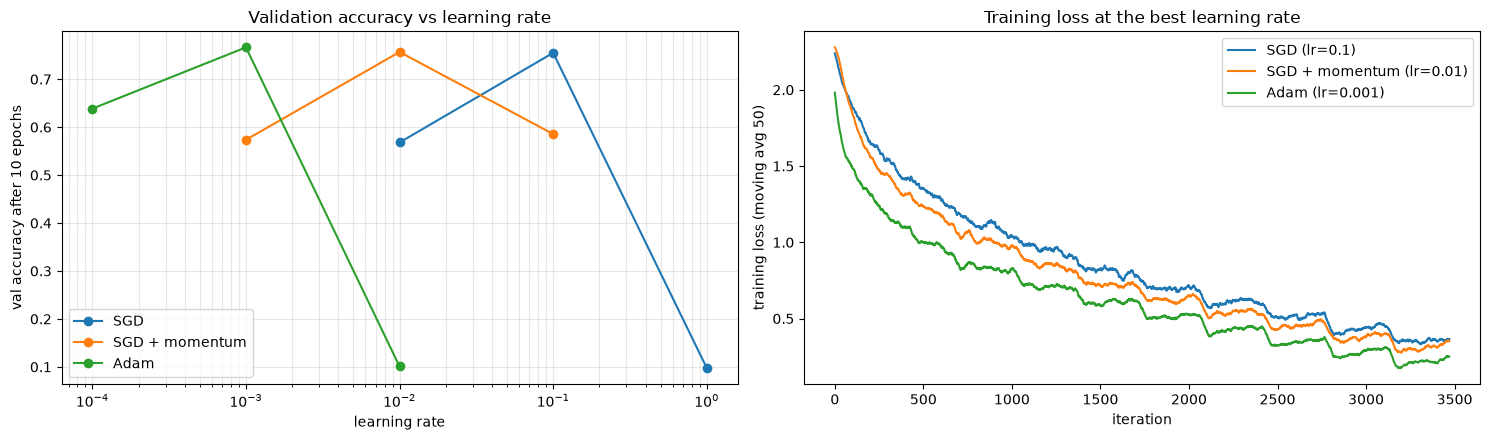

optimizer              lr  final val acc  best val acc  diverged
SGD                  0.01         0.5680        0.5680     False
SGD                   0.1         0.7550        0.7550     False
SGD                     1         0.0976        0.2896      True
SGD + momentum      0.001         0.5736        0.5736     False
SGD + momentum       0.01         0.7568        0.7568     False
SGD + momentum        0.1         0.5856        0.6368     False
Adam               0.0001         0.6386        0.6386     False
Adam                0.001         0.7664        0.7664     False
Adam                 0.01         0.1008        0.1064     False


In [10]:
# Task 2(c): small CNN (no batch norm) with plain SGD, SGD + momentum, Adam at three learning rates each
EPOCHS_2C = 10
GRID_2C = {
    'SGD':            (lambda ps, lr: MySGD(ps, lr=lr),               [0.01, 0.1, 1.0]),
    'SGD + momentum': (lambda ps, lr: MySGD(ps, lr=lr, momentum=0.9), [0.001, 0.01, 0.1]),
    'Adam':           (lambda ps, lr: MyAdam(ps, lr=lr),              [1e-4, 1e-3, 1e-2]),
}

def run_2c(make_opt, lr):
    set_seed()
    model = SmallCNN(bn=False).to(device)
    return fit(model, make_opt(model.parameters(), lr), TensorLoader(Xtr_d, ytr_d, 128, shuffle=True),
               EPOCHS_2C, amp=False)

res_2c = {}
for name, (make_opt, lrs) in GRID_2C.items():
    for lr in lrs:
        print(f'{name}, lr={lr}')
        res_2c[(name, lr)] = cached(f'2c_{name}_{lr}'.replace(' ', ''), lambda: run_2c(make_opt, lr))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
best_2c = {}
for name, (_, lrs) in GRID_2C.items():
    accs = [res_2c[(name, lr)]['val_acc'][-1] for lr in lrs]
    best_2c[name] = lrs[int(np.argmax(accs))]
    ax[0].semilogx(lrs, accs, 'o-', label=name)
    h = res_2c[(name, best_2c[name])]
    ax[1].plot(smooth(h['iter_loss'], 50), label=f'{name} (lr={best_2c[name]})')
ax[0].set(xlabel='learning rate', ylabel=f'val accuracy after {EPOCHS_2C} epochs', title='Validation accuracy vs learning rate')
ax[0].legend(); ax[0].grid(True, which='both', alpha=0.3)
ax[1].set(xlabel='iteration', ylabel='training loss (moving avg 50)', title='Training loss at the best learning rate')
ax[1].legend()
plt.tight_layout(); plt.show()

print(f"{'optimizer':16s} {'lr':>8s} {'final val acc':>14s} {'best val acc':>13s} {'diverged':>9s}")
for (name, lr), h in res_2c.items():
    print(f"{name:16s} {lr:8g} {h['val_acc'][-1]:14.4f} {max(h['val_acc']):13.4f} {str(h['diverged']):>9s}")

**Discussion**

Best results after 10 epochs: Adam at lr = 1e-3 gets **76.6%**, SGD + momentum at 0.01 gets 75.7%, and plain SGD at 0.1 gets 75.5%. At their best learning rates, all three end up in about the same place.

The real difference is how sensitive each one is to the learning rate:

- **Plain SGD:** at 0.01 it's too slow (56.8%), and at 1.0 the loss blows up to NaN.
- **SGD + momentum:** with μ = 0.9, the effective step is about 10× the learning rate. So momentum at 0.01 behaves like plain SGD at 0.1, which is exactly why those two are each one's best. At 0.1 the training loss starts rising again after epoch 6 and accuracy drops to 58.6%.
- **Adam:** great at 1e-3, but at 1e-2 it gets stuck at 10% accuracy (random guessing) from epoch 2 onwards, with the loss frozen at ln 10 ≈ 2.303. Most likely the big early steps killed the ReLU units, so no gradient flows anymore. It isn't marked as diverged because the loss never becomes NaN.

Looking at the training loss at the best rates: Adam drops fastest, then momentum, then plain SGD. But Adam also has the biggest train/val gap (92% vs 77%), so faster training didn't translate into better generalisation.

Overall, every optimizer only works well within about one order of magnitude of learning rate, so the learning rate matters more than the choice of optimizer.

## Task 3: Regularization and residual connections

### 3(a) Regularization with 5k training images

baseline


weight decay


dropout


flip+crop


cutout


mixup


all combined


              train acc  val acc  gap (train - val)  best val acc
baseline         1.0000   0.6332             0.3668        0.6378
weight decay     1.0000   0.6408             0.3592        0.6446
dropout          0.9900   0.6622             0.3278        0.6662
flip+crop        0.9040   0.7208             0.1832        0.7226
cutout           0.9998   0.6614             0.3384        0.6642
mixup            0.9986   0.6356             0.3630        0.6460
all combined     0.6244   0.5920             0.0324        0.5978


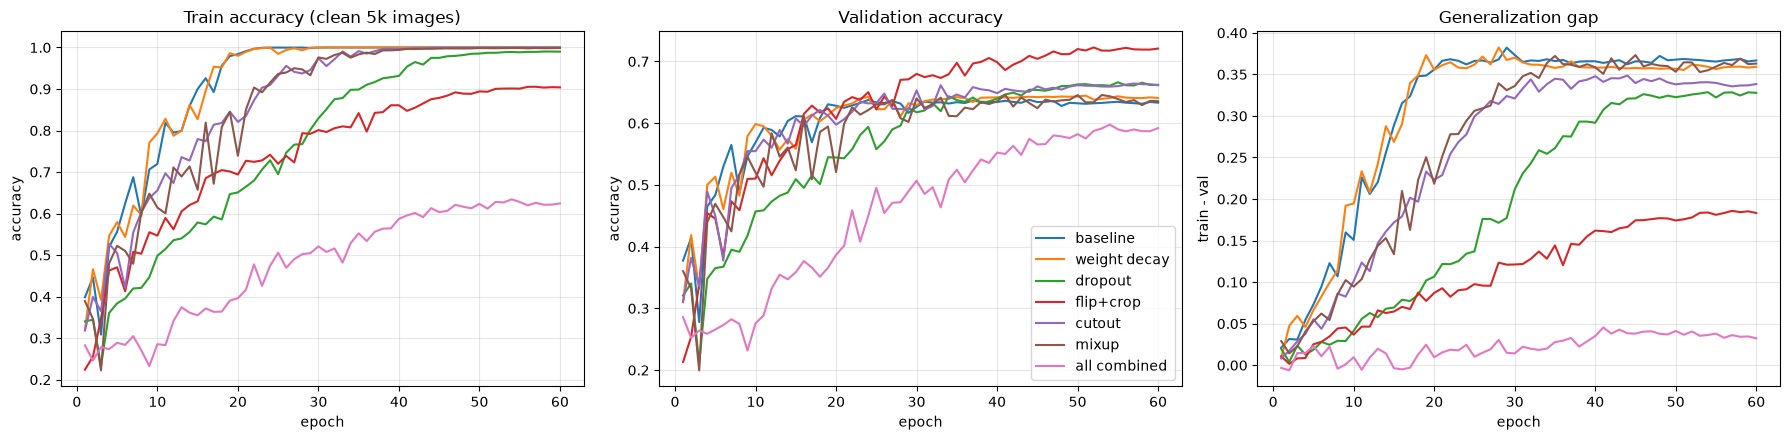

In [11]:
# Task 3(a): regularization on 5k training images, small CNN with batch norm
import pandas as pd

EPOCHS_3A = 60
X5k, y5k = Xtr_d[:5000], ytr_d[:5000]           # first 5k of the already-shuffled 45k train split

CONFIGS_3A = {
    'baseline':     dict(),
    'weight decay': dict(wd=5e-4),
    'dropout':      dict(dropout=0.5),
    'flip+crop':    dict(aug=[flip_crop]),
    'cutout':       dict(aug=[cutout]),
    'mixup':        dict(mixup=1.0),
    'all combined': dict(wd=5e-4, dropout=0.5, aug=[flip_crop, cutout], mixup=1.0),
}

def run_3a(cfg):
    set_seed()
    model = SmallCNN(bn=True, dropout=cfg.get('dropout', 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=cfg.get('wd', 0.0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_3A)
    aug = compose(*cfg['aug']) if cfg.get('aug') else None
    return fit(model, opt, TensorLoader(X5k, y5k, 128, shuffle=True), EPOCHS_3A, sched=sched, augment=aug,
               mixup_alpha=cfg.get('mixup', 0.0), clean_train_dl=TensorLoader(X5k, y5k, 512), verbose=False)

res_3a = {}
for name, cfg in CONFIGS_3A.items():
    print(name)
    res_3a[name] = cached(f'3a_{name}'.replace(' ', '_').replace('+', '_'), lambda: run_3a(cfg))

table_3a = pd.DataFrame({
    name: {'train acc': h['train_acc'][-1], 'val acc': h['val_acc'][-1],
           'gap (train - val)': h['train_acc'][-1] - h['val_acc'][-1], 'best val acc': max(h['val_acc'])}
    for name, h in res_3a.items()}).T
print(table_3a.to_string(float_format='{:.4f}'.format))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ep_x = range(1, EPOCHS_3A + 1)
for name, h in res_3a.items():
    ax[0].plot(ep_x, h['train_acc'], label=name)
    ax[1].plot(ep_x, h['val_acc'], label=name)
    ax[2].plot(ep_x, np.array(h['train_acc']) - np.array(h['val_acc']), label=name)
ax[0].set(xlabel='epoch', ylabel='accuracy', title='Train accuracy (clean 5k images)')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='Validation accuracy')
ax[2].set(xlabel='epoch', ylabel='train - val', title='Generalization gap')
for a in ax:
    a.grid(alpha=0.3)
ax[1].legend()
plt.tight_layout(); plt.show()

**Discussion**

With only 5k images, the baseline memorises the training set (100% train accuracy by about epoch 25) but gets only **63.3%** on validation, a gap of 0.37.

| Method | Val acc | Change vs baseline |
|---|---|---|
| Flip + crop | 72.1% | **+8.8** |
| Dropout | 66.2% | +2.9 |
| Cutout | 66.1% | +2.8 |
| Weight decay | 64.1% | +0.8 |
| Mixup | 63.6% | +0.2 |
| All combined | 59.2% | **−4.1** |

- **Flip + crop is clearly the best.** It creates realistic new training images (a mirrored or slightly shifted car is still a car), so the model can't simply memorise. Train accuracy stays at 90% and the gap halves.
- **Dropout and cutout help a bit.** Dropout delays memorisation (its gap curve rises much later), and cutout forces the model to look at the whole object instead of one patch.
- **Weight decay and mixup barely help here.** With batch norm, weight decay mostly changes the effective learning rate rather than limiting the model. Mixup still let the model reach 99.9% clean train accuracy, so it didn't stop memorisation.
- **All combined has almost no gap (0.03), but it has the worst validation accuracy.** Train accuracy is only 62%, so the model is underfitting. Stacking every regulariser made the task too hard for this small CNN to learn in 60 epochs.

Overall, a small gap isn't the goal by itself. Too much regularisation hurts as much as too little.

### 3(b) Plain vs residual networks

In [12]:
# Task 3(b): CIFAR-style plain / residual networks of depth 6n + 2
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.residual, self.stride, self.extra = residual, stride, cout - cin

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            sc = x
            if self.stride != 1 or self.extra:
                # parameter-free shortcut (option A): subsample + zero-pad channels,
                # so plain and residual nets have exactly the same parameters
                sc = F.pad(x[:, :, ::self.stride, ::self.stride],
                           (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))
            out = out + sc
        return F.relu(out)


class CifarResNet(nn.Module):
    def __init__(self, depth, residual=True, widths=(16, 32, 64), num_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        blocks, cin = [], widths[0]
        for i, w in enumerate(widths):
            for k in range(n):
                blocks.append(Block(cin, w, 2 if (i > 0 and k == 0) else 1, residual))
                cin = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

for d in [8, 20, 56]:
    print(f'depth {d:2d}: plain {n_params(CifarResNet(d, False)):,} params, residual {n_params(CifarResNet(d, True)):,} params')

depth  8: plain 75,290 params, residual 75,290 params
depth 20: plain 269,722 params, residual 269,722 params
depth 56: plain 853,018 params, residual 853,018 params


plain-8


residual-8


plain-20


residual-20


plain-56


residual-56


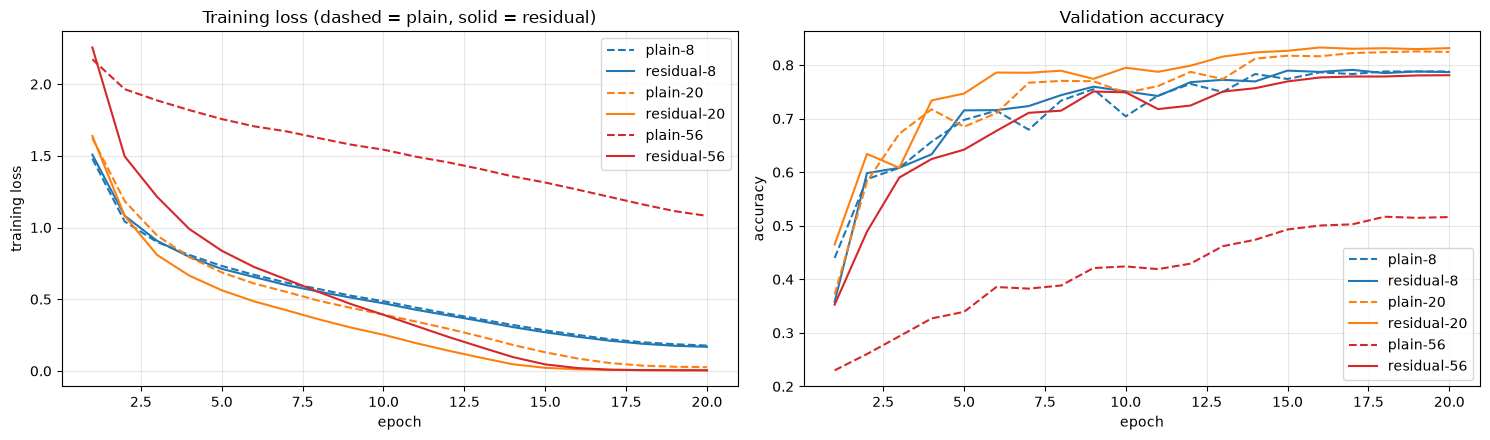

model         final train loss  final val acc  time (s)
plain-8                 0.1770         0.7880       105
residual-8              0.1682         0.7868       106
plain-20                0.0262         0.8244       168
residual-20             0.0050         0.8316       177
plain-56                1.0810         0.5162       323
residual-56             0.0041         0.7810       327


In [13]:
EPOCHS_3B = 20
DEPTHS = [8, 20, 56]

def run_3b(depth, residual):
    set_seed()
    model = CifarResNet(depth, residual).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_3B)
    return fit(model, opt, TensorLoader(Xtr_d, ytr_d, 128, shuffle=True), EPOCHS_3B, sched=sched, verbose=False)

res_3b = {}
for d in DEPTHS:
    for residual in [False, True]:
        key = f"{'residual' if residual else 'plain'}-{d}"
        print(key)
        res_3b[key] = cached(f'3b_{key}', lambda: run_3b(d, residual))

colors = dict(zip(DEPTHS, ['tab:blue', 'tab:orange', 'tab:red']))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ep_x = range(1, EPOCHS_3B + 1)
for d in DEPTHS:
    for residual, ls in [(False, '--'), (True, '-')]:
        key = f"{'residual' if residual else 'plain'}-{d}"
        ax[0].plot(ep_x[:len(res_3b[key]['train_loss'])], res_3b[key]['train_loss'], ls, color=colors[d], label=key)
        ax[1].plot(ep_x[:len(res_3b[key]['val_acc'])], res_3b[key]['val_acc'], ls, color=colors[d], label=key)
ax[0].set(xlabel='epoch', ylabel='training loss', title='Training loss (dashed = plain, solid = residual)')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='Validation accuracy')
for a in ax:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'model':12s} {'final train loss':>17s} {'final val acc':>14s} {'time (s)':>9s}")
for key, h in res_3b.items():
    print(f"{key:12s} {h['train_loss'][-1]:17.4f} {h['val_acc'][-1]:14.4f} {h['time']:9.0f}")

**Discussion**

- **Depth 8:** plain and residual are basically the same (val 78.8% vs 78.7%). Shallow networks are easy to train either way.
- **Depth 20:** residual already trains faster and to a lower loss (0.005 vs 0.026).
- **Depth 56:** this is where it breaks down.
  - The plain-56 training loss is still **1.08** after 20 epochs, worse than plain-20 and even plain-8, and it only reaches 51.6% validation accuracy.
  - Residual-56 trains without trouble, down to a loss of 0.004.

This is the degradation problem:
- In theory, a deeper network should do at least as well as a shallower one, because the extra layers could just learn to pass their input through.
- In practice, plain-56 has a *higher training loss*. That rules out overfitting: the network simply can't be optimised well.
- With a shortcut, each block only has to learn a small change on top of the identity, and gradients have a direct path back to the early layers. So adding depth no longer makes training harder.
- Plain and residual networks have exactly the same parameters (the shortcut adds none), so the shortcut is the only difference.

Also, residual-56 (78.1%) generalises worse than residual-20 (83.2%) despite a lower training loss. With 853k parameters, no augmentation and 20 epochs, it overfits. The shortcut fixes trainability, not overfitting.

## Task 4: Best CNN

### Ablation study

parameters: 453,476
final (all)


  ep   1  loss 1.8099  train acc 0.3879  val acc 0.5218  (9s)


  ep   2  loss 1.4949  train acc 0.5475  val acc 0.5170  (17s)


  ep   3  loss 1.3480  train acc 0.6244  val acc 0.6026  (26s)


  ep   4  loss 1.2363  train acc 0.6793  val acc 0.6784  (35s)


...

  ep  17  loss 0.7535  train acc 0.9048  val acc 0.8940  (159s)


  ep  18  loss 0.7371  train acc 0.9110  val acc 0.8984  (172s)


  ep  19  loss 0.7274  train acc 0.9165  val acc 0.8992  (185s)


  ep  20  loss 0.7216  train acc 0.9195  val acc 0.8984  (198s)


                     final val acc best val acc final train loss time (s)
final (all)                 0.8988       0.8988           0.7228      176
no shortcut                 0.8986       0.8986           0.7189      165
no augmentation             0.8594       0.8612           0.5257      167
no weight decay             0.8852       0.8852           0.7518      177
AdamW instead of SGD        0.8984       0.8992           0.7216      198


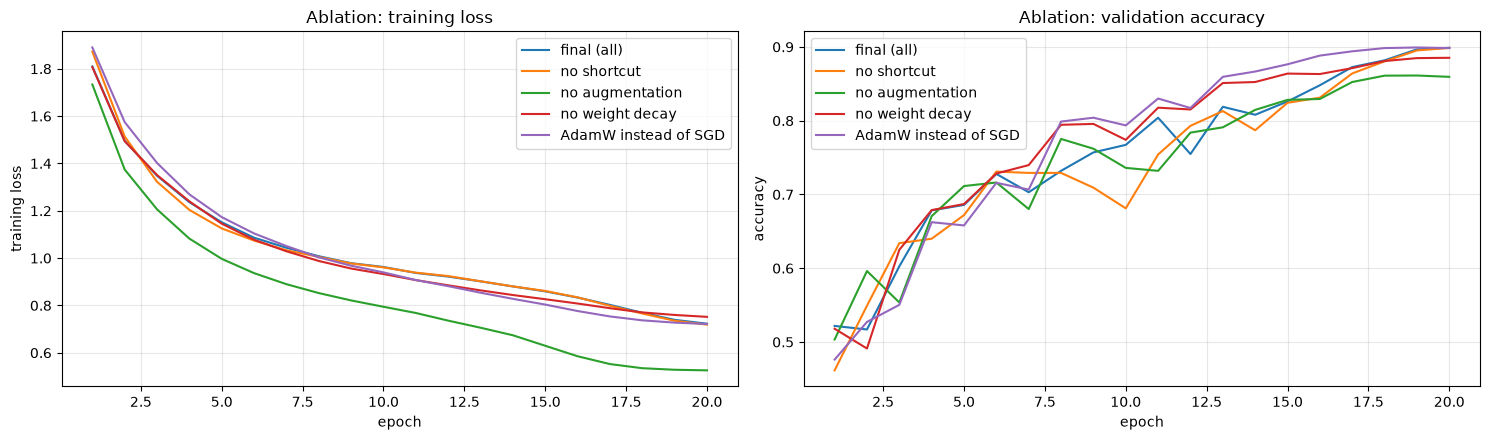

In [14]:
# Task 4: best CNN with <= 500k parameters and <= 20 epochs (needs the CifarResNet class from Task 3(b))
EPOCHS_4 = 20
WIDTHS_4 = (26, 52, 104)
DEPTH_4 = 14

def build_t4(residual=True):
    return CifarResNet(DEPTH_4, residual, widths=WIDTHS_4)

print(f'parameters: {n_params(build_t4()):,}')
assert n_params(build_t4()) <= 500_000

BASE_4 = dict(residual=True, aug=True, wd=5e-4, opt='sgd')
ABLATIONS_4 = {
    'final (all)':         {},
    'no shortcut':         {'residual': False},
    'no augmentation':     {'aug': False},
    'no weight decay':     {'wd': 0.0},
    'AdamW instead of SGD': {'opt': 'adamw'},
}

def run_4(over):
    cfg = {**BASE_4, **over}
    set_seed()
    model = build_t4(cfg['residual']).to(device)
    train_dl = TensorLoader(Xtr_d, ytr_d, 128, shuffle=True)
    if cfg['opt'] == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
        max_lr = 0.1
    else:   # decoupled weight decay is the fair way to use weight decay with Adam
        opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.05 if cfg['wd'] > 0 else 0.0)
        max_lr = 3e-3
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, epochs=EPOCHS_4, steps_per_epoch=len(train_dl))
    aug = compose(flip_crop, lambda x: cutout(x, 8)) if cfg['aug'] else None
    hist = fit(model, opt, train_dl, EPOCHS_4, sched=sched, sched_per_iter=True, augment=aug,
               label_smoothing=0.1, verbose=True)
    hist['state_dict'] = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    return hist

res_4 = {}
for name, over in ABLATIONS_4.items():
    print(name)
    res_4[name] = cached(f'4_{name}'.replace(' ', '_').replace('(', '').replace(')', ''), lambda: run_4(over))

table_4 = pd.DataFrame({
    name: {'final val acc': h['val_acc'][-1], 'best val acc': max(h['val_acc']),
           'final train loss': h['train_loss'][-1], 'time (s)': h['time']}
    for name, h in res_4.items()}).T
fmt = {c: '{:.4f}'.format for c in ['final val acc', 'best val acc', 'final train loss']}
fmt['time (s)'] = '{:.0f}'.format
print(table_4.to_string(formatters=fmt))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for name, h in res_4.items():
    ax[0].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], label=name)
    ax[1].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], label=name)
ax[0].set(xlabel='epoch', ylabel='training loss', title='Ablation: training loss')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='Ablation: validation accuracy')
for a in ax:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Discussion**

The final model is a ResNet-14 widened to 26/52/104 channels (453,476 parameters), trained for 20 epochs with:
- Nesterov SGD with a one-cycle learning-rate schedule (peak 0.1)
- weight decay 5e-4 and label smoothing 0.1
- flip + crop + 8 px cutout augmentation

In the ablation below, each row removes or changes one thing.

| Change | Final val acc | Δ |
|---|---|---|
| Final (all) | 89.88% | – |
| No augmentation | 85.94% | **−3.9** |
| No weight decay | 88.52% | −1.4 |
| No shortcut | 89.86% | 0.0 |
| AdamW instead of SGD | 89.84% | 0.0 |

- **Augmentation matters most.** Without it the model hits 100% train accuracy and validation stalls at 86%. It memorises, just like in Task 3(a).
- **Weight decay** adds another 1.4 points.
- **The shortcut makes no difference at 14 layers.** That matches Task 3(b), where depth 8 and 20 trained fine without shortcuts. It was kept anyway, since it adds no extra parameters and makes the network safe to deepen.
- **AdamW performs the same as tuned SGD.** With a single seed, differences under about 0.5 points are just noise.

A couple of other things:
- Most of the accuracy comes in the last 10 epochs (≈80% → 90%) as the one-cycle schedule lowers the learning rate.
- The training loss stays around 0.72 because label smoothing stops it from going much lower.

### Test accuracy

In [15]:
# Task 4: single evaluation of the final model on the test set
final_model = build_t4(True).to(device)
final_model.load_state_dict(res_4['final (all)']['state_dict'])
test_dl = TensorLoader(X_test.to(device), y_test.to(device), batch_size=512)
test_loss, test_acc = evaluate(final_model, test_dl)
print(f'final model: {n_params(final_model):,} parameters, {EPOCHS_4} epochs')
print(f'TEST accuracy: {test_acc:.4f}   (test loss {test_loss:.4f})')

final model: 453,476 parameters, 20 epochs
TEST accuracy: 0.8976   (test loss 0.3531)


**Discussion**

- **Test accuracy: 89.76%**, evaluated once on the 10,000 test images (453,476 parameters, 20 epochs).
- This is within 0.1 points of the validation accuracy (89.88%). So choosing the design on the validation set didn't overfit to it, and the 5k validation split was a reliable stand-in for the test set.
- The test loss (0.35) is lower than the training loss (0.72). That's expected: the training loss includes label smoothing and is measured on augmented images, while the test loss is plain cross-entropy on clean images.

## Use of AI tools

Claude (Anthropic's AI assistant) was used while working on this assignment, to help write and debug the code, set up the Python environment and run the experiments. All of the code and results were reviewed by the author.